# Task 2 – Feature Extraction and Image Matching (Unit 4)

**Input:** my photograph `data/photo1.jpg` and a second photograph of the same scene `data/photo2.jpg`. The second one was taken from a different position, with a different pose.

**What this notebook does**
1. Extract and visualise **HOG** (Histogram of Oriented Gradients) features
2. Detect **SIFT** keypoints and compute descriptors
3. Match SIFT features between the two photos
4. Repeat the matching after **rotating** and **resizing** one image
5. Display and compare the matching quality

Outputs are saved to `outputs/task2/`.

## 0. Setup

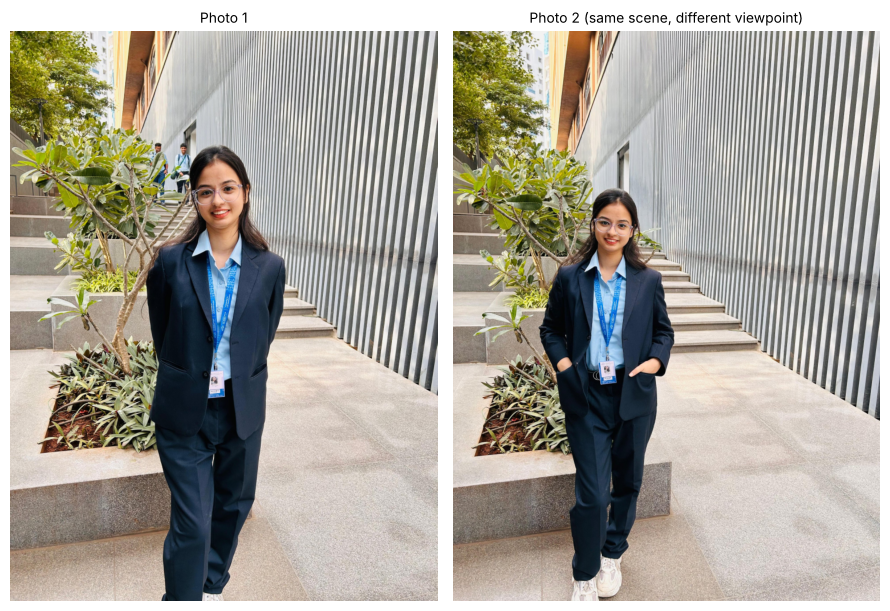

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
OUT = "outputs/task2"
os.makedirs(OUT, exist_ok=True)


def show(images, titles, cols=3, size=4.0, suptitle=None, save_as=None):
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size * h / w + 0.45) + 0.5))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray")
        ax.set_title(t, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(f"{OUT}/{save_as}", dpi=110)
    plt.show()


def load(path, width=750):
    im = cv2.imread(path)
    return cv2.resize(im, (width, int(im.shape[0] * width / im.shape[1])), interpolation=cv2.INTER_AREA)


p1, p2 = load("data/photo1.jpg"), load("data/photo2.jpg")
show([p1, p2], ["Photo 1", "Photo 2 (same scene, different viewpoint)"], cols=2, size=4.5)

## 1. HOG – Histogram of Oriented Gradients
HOG describes shape through the distribution of edge directions:
1. Compute the gradient (magnitude and direction) at every pixel.
2. Divide the image into **16×16-pixel cells** and build a **9-bin histogram** of gradient directions in each cell.
3. Group cells into **2×2 blocks** and normalise each block (L2-Hys), which makes the features robust to lighting changes.
4. Concatenate all block histograms into one long feature vector.

The visualisation draws the dominant gradient directions in each cell. Strong lines follow the person's outline, the steps and the vertical wall fins.

HOG feature vector length: 98820
  = 45 x 61 blocks x (2x2 cells) x 9 orientation bins = 98820


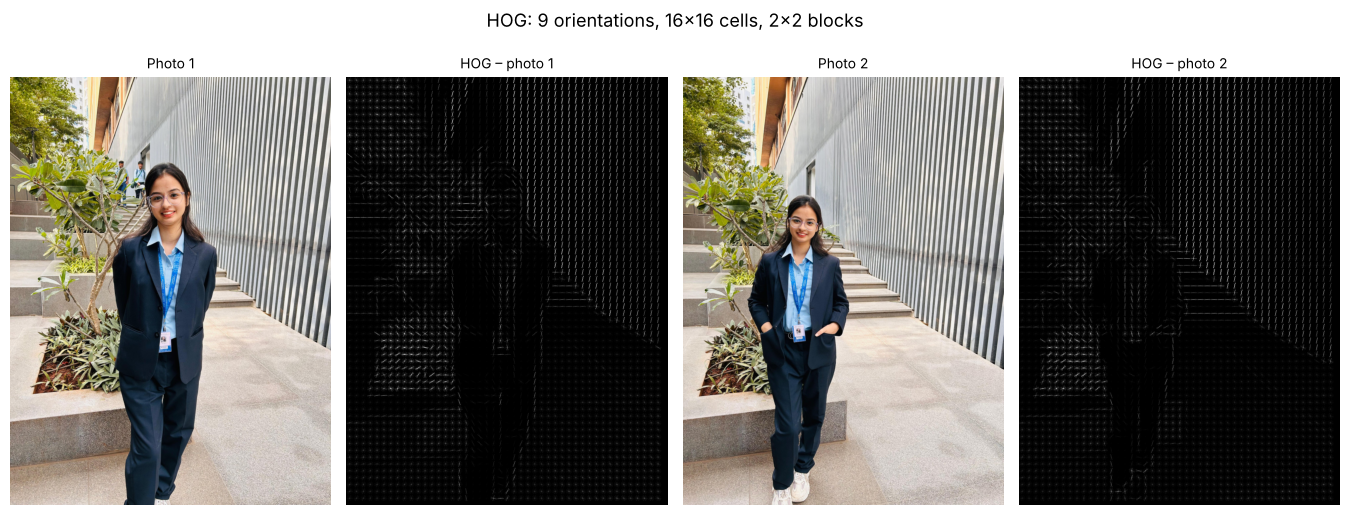

In [2]:
def hog_features(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    feats, hog_img = hog(gray, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2),
                         block_norm="L2-Hys", visualize=True, feature_vector=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() * 0.5))
    return feats, (hog_img * 255).astype(np.uint8)


f1, h1 = hog_features(p1)
f2, h2 = hog_features(p2)
cv2.imwrite(f"{OUT}/hog_photo1.png", h1)
cv2.imwrite(f"{OUT}/hog_photo2.png", h2)
print("HOG feature vector length:", len(f1))
n_cells_x, n_cells_y = p1.shape[1] // 16, p1.shape[0] // 16
print(f"  = {n_cells_x - 1} x {n_cells_y - 1} blocks x (2x2 cells) x 9 orientation bins "
      f"= {(n_cells_x - 1) * (n_cells_y - 1) * 36}")

show([p1, h1, p2, h2], ["Photo 1", "HOG – photo 1", "Photo 2", "HOG – photo 2"],
     cols=4, size=3.4, suptitle="HOG: 9 orientations, 16×16 cells, 2×2 blocks", save_as="fig1_hog.png")

In [3]:
# HOG as a global descriptor: cosine similarity between the two photos
cos_sim = np.dot(f1, f2) / (np.linalg.norm(f1) * np.linalg.norm(f2))
print(f"Cosine similarity of HOG vectors (photo 1 vs photo 2): {cos_sim:.3f}")

Cosine similarity of HOG vectors (photo 1 vs photo 2): 0.838


The two HOG vectors are similar (cosine ≈ 0.84) because the scene layout matches: the wall on the right, the plants on the left and a person in the centre. HOG is a **dense, position-dependent** descriptor. That makes it good for recognising object *shape* (it is the classic feature for pedestrian detection), but it cannot match individual points between images taken from different viewpoints. For that we need SIFT.

## 2. SIFT keypoints and descriptors
**SIFT (Scale-Invariant Feature Transform)**:
1. Builds a scale space (Difference-of-Gaussians) and finds extrema, which are blob-like points that are stable across scales.
2. Removes low-contrast and edge points.
3. Assigns each keypoint a dominant **orientation**, which gives rotation invariance.
4. Describes the patch around it with a **128-value** descriptor (4×4 sub-regions × 8 orientation bins).

In the plot, the circle size shows the keypoint's scale and the line inside shows its orientation.

Photo 1: 3780 keypoints, descriptor array shape (3780, 128)
Photo 2: 3294 keypoints, descriptor array shape (3294, 128)
Example descriptor (first 16 of 128 values): [ 0  0  3  5 17 30  6  0 87  2  8 12 21 20  1 16]


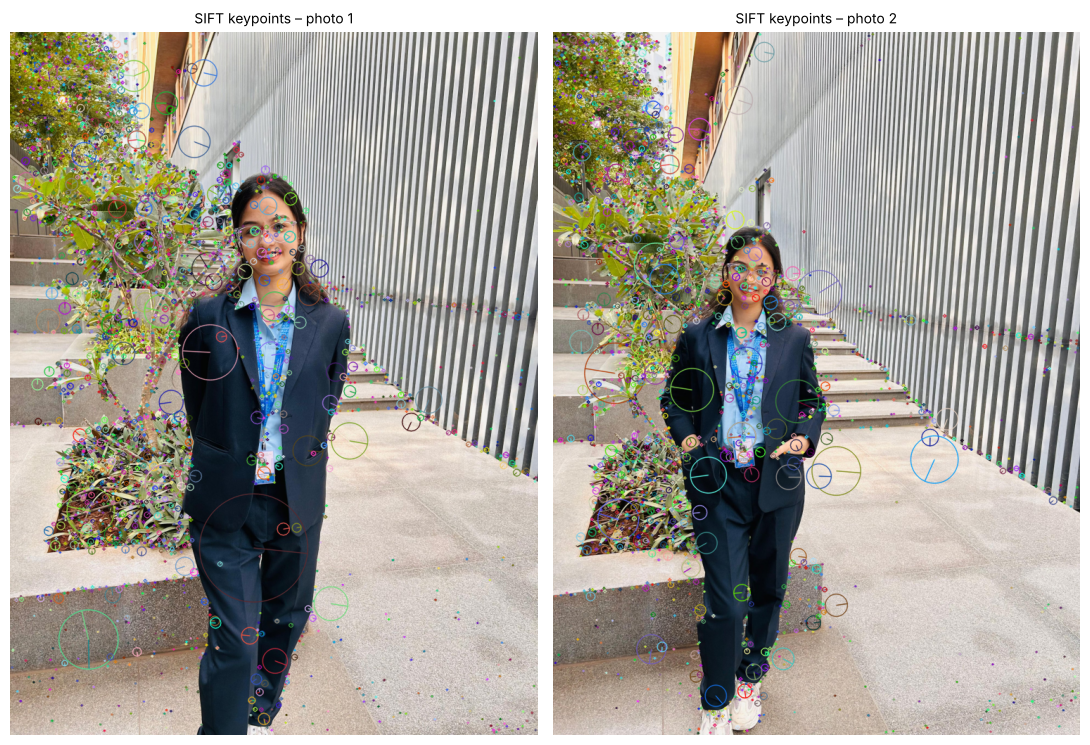

In [4]:
sift = cv2.SIFT_create()

def detect(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return sift.detectAndCompute(gray, None)

kp1, des1 = detect(p1)
kp2, des2 = detect(p2)
print(f"Photo 1: {len(kp1)} keypoints, descriptor array shape {des1.shape}")
print(f"Photo 2: {len(kp2)} keypoints, descriptor array shape {des2.shape}")
print("Example descriptor (first 16 of 128 values):", des1[0][:16].astype(int))

vis1 = cv2.drawKeypoints(p1, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
vis2 = cv2.drawKeypoints(p2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
cv2.imwrite(f"{OUT}/sift_keypoints_photo1.jpg", vis1)
cv2.imwrite(f"{OUT}/sift_keypoints_photo2.jpg", vis2)
show([vis1, vis2], ["SIFT keypoints – photo 1", "SIFT keypoints – photo 2"], cols=2, size=5.5,
     save_as="fig2_sift_keypoints.png")

Most keypoints sit on textured areas such as the leaves, the steps, the edges of the wall fins and the face. Flat areas like the floor and the plain suit fabric give very few.

## 3. Matching SIFT features
**Matching pipeline:**
1. **Brute-force matcher** (L2 distance): for every descriptor in image A, find its **2 nearest** descriptors in image B.
2. **Lowe's ratio test:** keep a match only if the best distance is less than 0.75 × the second-best. This removes ambiguous matches, for example on repetitive wall fins.
3. **RANSAC homography:** keep only matches that agree with one geometric transformation. These are the *inliers*; the rest are outliers.

In the figures, **green** lines are a sample of 60 inliers and **red** lines are 20 rejected matches.

In [5]:
bf = cv2.BFMatcher(cv2.NORM_L2)
RATIO = 0.75


def match(img_a, img_b):
    ka, da = detect(img_a)
    kb, db = detect(img_b)
    knn = bf.knnMatch(da, db, k=2)
    good = [m for m, n in knn if m.distance < RATIO * n.distance]
    src = np.float32([ka[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kb[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    inlier = mask.ravel().astype(bool)
    return ka, kb, knn, good, inlier


def draw_matches(img_a, img_b, ka, kb, good, inlier, n_in=60, n_out=20):
    rs = np.random.default_rng(0)
    h = max(img_a.shape[0], img_b.shape[0])
    canvas = np.zeros((h, img_a.shape[1] + img_b.shape[1], 3), np.uint8)
    canvas[:img_a.shape[0], :img_a.shape[1]] = img_a
    canvas[:img_b.shape[0], img_a.shape[1]:] = img_b
    off = np.array([img_a.shape[1], 0])
    sel_out = rs.permutation(np.flatnonzero(~inlier))[:n_out]
    sel_in = rs.permutation(np.flatnonzero(inlier))[:n_in]
    for idxs, col in [(sel_out, (0, 0, 255)), (sel_in, (0, 255, 0))]:
        for i in idxs:
            a = tuple(np.int32(ka[good[i].queryIdx].pt))
            b = tuple(np.int32(np.array(kb[good[i].trainIdx].pt) + off))
            cv2.line(canvas, a, b, col, 2, cv2.LINE_AA)
            cv2.circle(canvas, a, 4, col, -1)
            cv2.circle(canvas, b, 4, col, -1)
    return canvas

### 3a. Photo 1 vs Photo 2 (original)

955 good matches after the ratio test, 795 RANSAC inliers (83.2%)


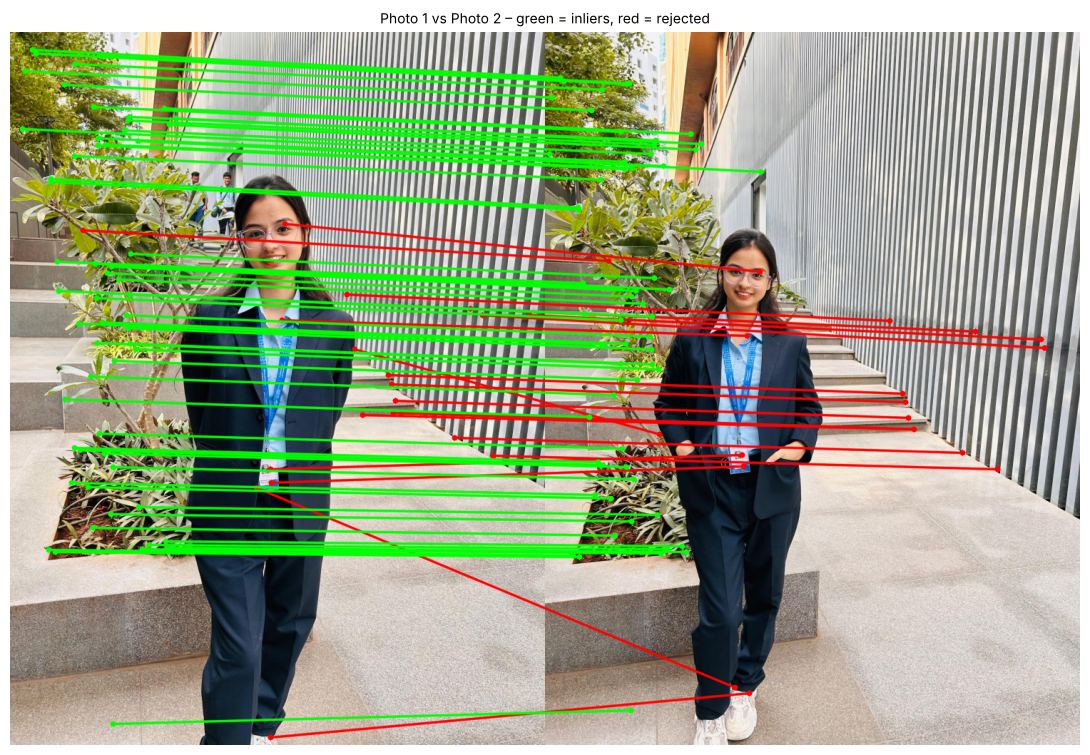

In [6]:
ka, kb, knn, good, inl = match(p1, p2)
vis = draw_matches(p1, p2, ka, kb, good, inl)
cv2.imwrite(f"{OUT}/match_1_original.jpg", vis)
print(f"{len(good)} good matches after the ratio test, {inl.sum()} RANSAC inliers ({100 * inl.mean():.1f}%)")
show([vis], ["Photo 1 vs Photo 2 – green = inliers, red = rejected"], cols=1, size=11)

## 4. Repeat the experiment after rotating and resizing
I transform **photo 2** in three ways and match it against photo 1 again:
- rotated by 30°
- resized to 0.5× (half the resolution)
- resized to 0.6× **and** rotated by −45°

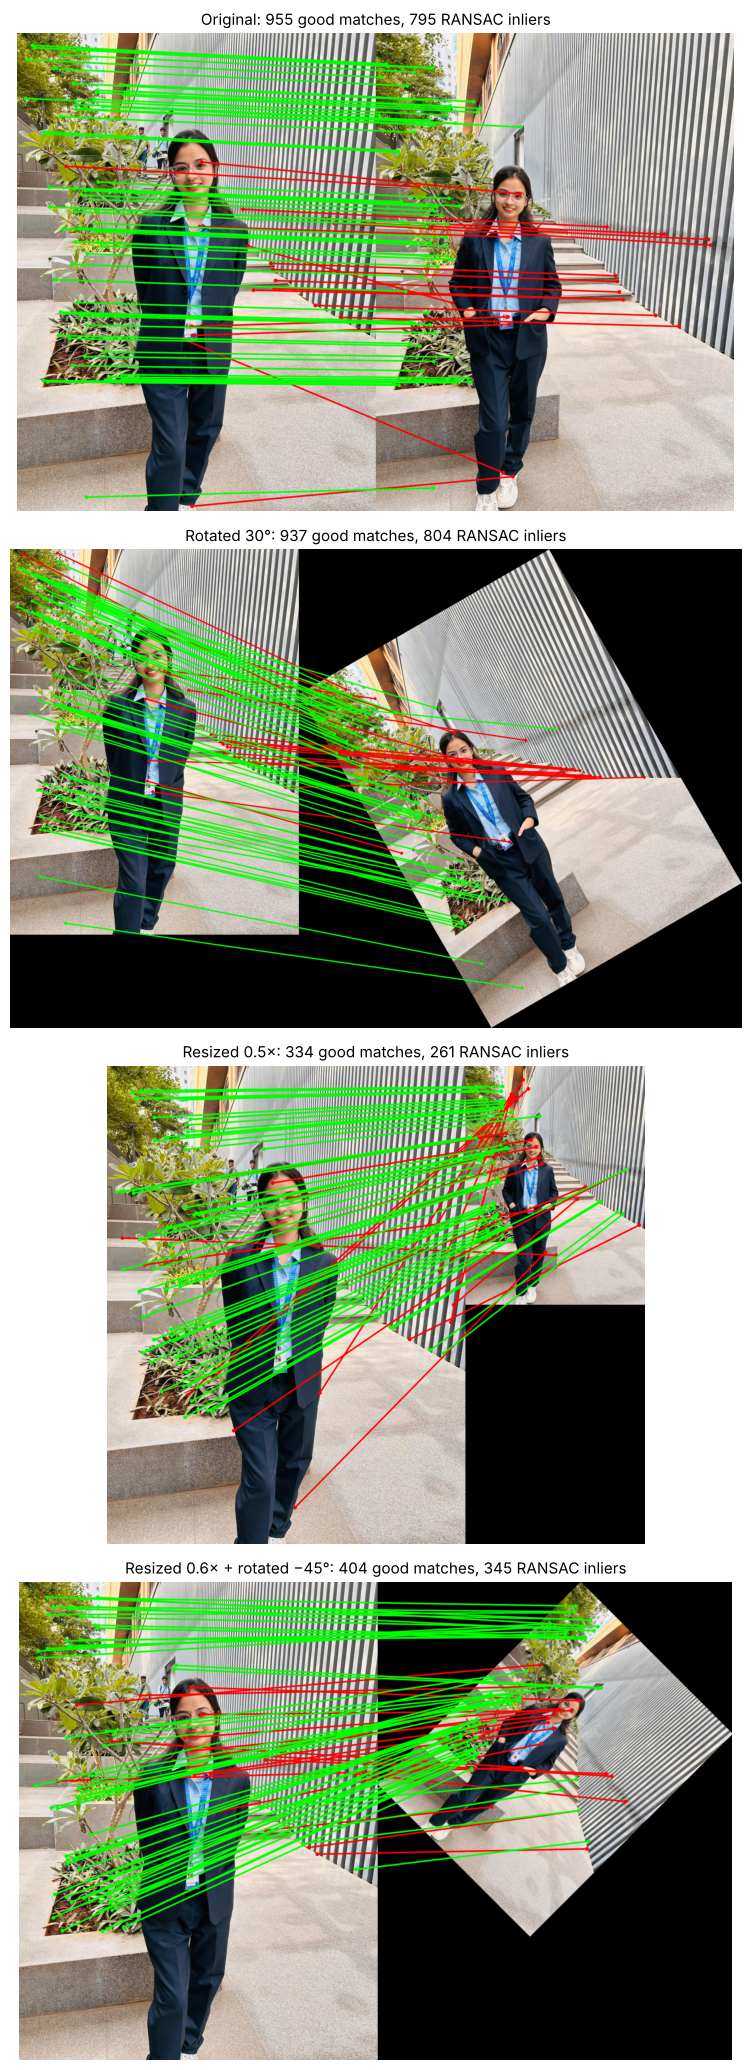

In [7]:
def rotate(img, angle):
    h, w = img.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)   # enlarge canvas so nothing is cut off
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(img, M, (nw, nh))


experiments = {
    "Original": p2,
    "Rotated 30°": rotate(p2, 30),
    "Resized 0.5×": cv2.resize(p2, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA),
    "Resized 0.6× + rotated −45°": rotate(cv2.resize(p2, None, fx=0.6, fy=0.6, interpolation=cv2.INTER_AREA), -45),
}

rows, figs = [], []
for i, (name, img_b) in enumerate(experiments.items(), 1):
    ka, kb, knn, good, inl = match(p1, img_b)
    vis = draw_matches(p1, img_b, ka, kb, good, inl)
    cv2.imwrite(f"{OUT}/match_{i}_{name.split()[0].lower()}.jpg", vis)
    figs.append((name, vis, len(good), inl.sum()))
    rows.append([f"Photo 1 vs Photo 2 – {name}", len(ka), len(kb), len(knn), len(good), int(inl.sum()),
                 f"{100 * inl.mean():.1f}%", round(float(np.mean([m.distance for m in good])), 1)])

fig, axes = plt.subplots(len(figs), 1, figsize=(11, 5.2 * len(figs)))
for ax, (name, vis, g, n) in zip(axes, figs):
    ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{name}: {g} good matches, {n} RANSAC inliers", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_matching_comparison.png", dpi=100); plt.show()

## 5. Comparison of matching quality

In [8]:
table_matching = pd.DataFrame(rows, columns=["Experiment", "Keypoints A", "Keypoints B", "Raw matches",
                                             "Good matches (ratio < 0.75)", "RANSAC inliers", "Inlier ratio",
                                             "Mean descriptor distance"])
table_matching.to_csv(f"{OUT}/table_matching.csv", index=False)
table_matching

,Experiment,Keypoints A,Keypoints B,Raw matches,Good matches (ratio < 0.75),RANSAC inliers,Inlier ratio,Mean descriptor distance
0,Photo 1 vs Photo 2 – Original,3780,3294,3780,955,795,83.2%,125.5
1,Photo 1 vs Photo 2 – Rotated 30°,3780,4077,3780,937,804,85.8%,131.4
2,Photo 1 vs Photo 2 – Resized 0.5×,3780,884,3780,334,261,78.1%,129.6
3,Photo 1 vs Photo 2 – Resized 0.6× + rotated −45°,3780,1735,3780,404,345,85.4%,137.6


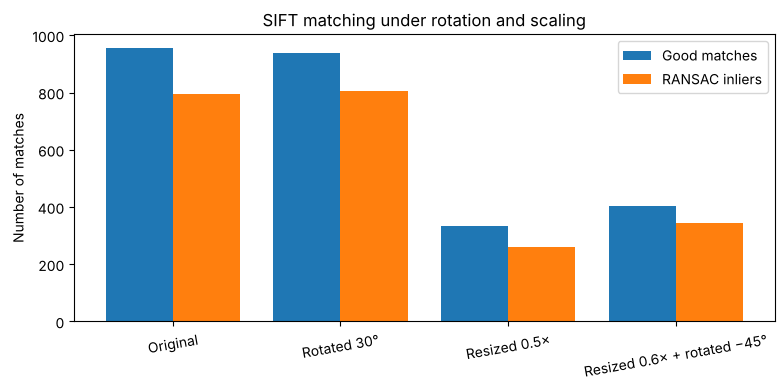

In [9]:
plt.figure(figsize=(8, 4))
x = np.arange(len(rows))
plt.bar(x - 0.2, [r[4] for r in rows], 0.4, label="Good matches")
plt.bar(x + 0.2, [r[5] for r in rows], 0.4, label="RANSAC inliers")
plt.xticks(x, list(experiments.keys()), rotation=10)
plt.ylabel("Number of matches"); plt.title("SIFT matching under rotation and scaling"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/fig4_matching_bar.png", dpi=110); plt.show()

**Observations:**
- **Rotation has almost no effect.** With 30° rotation the number of good matches stays about the same as the original, and the inlier ratio stays above 80%. This is because each SIFT descriptor is computed relative to the keypoint's own dominant orientation.
- **Downscaling reduces the number of matches.** At 0.5× size, photo 2 has far fewer keypoints because the fine texture disappears, so there are fewer matches. The inlier ratio, though, is still high (about 78%). SIFT's scale-space search still finds the *same* points at a different scale.
- **Combined scale and rotation** behaves like the scaling case. SIFT is invariant to both together.
- **Where the matches are:** most inliers lie on the **static background** (tree, plant bed, steps, wall). Matches on the **person** are often rejected (red) because the pose changed between the two photos (hands behind the back vs in the pockets). Non-rigid motion breaks the single-homography assumption.
- **Note on RANSAC:** a homography is exact for a pure rotation or scaling of the same image. For two real viewpoints of a 3D scene it is only approximate, which is why a few correct matches at different depths can be rejected.

## Summary of Task 2
| Feature | Type | Strength | Weakness |
|---|---|---|---|
| HOG | Dense, global shape descriptor | Robust to lighting; good for detecting object categories such as people | Position-dependent; not rotation- or scale-invariant; can't match points |
| SIFT | Sparse local keypoints | Invariant to rotation and scale; distinctive 128-D descriptors; reliable matching | Slower; few points on flat regions; repetitive patterns cause ambiguity |